# 05 — Final model: calibration, explainability, test set

The final steps on the **candidate final model: LightGBM tuned v2**
(`tuning/results/v2/best_params.json`, chosen in `notebooks/04_lightgbm.ipynb`
and section 3b-v2 of `docs/findings_log.md`), with the logistic regression as
the transparent benchmark.

**Scripts run, this notebook explains.** Every number here is produced by a
script in `src/` and saved in `reports/`; this notebook only reads those files
and comments on them (no training here).

| Section | Command (from the project root) | Output | Status |
|---|---|---|---|
| 1. Calibration of LightGBM v2 | `python3 -m src.evaluate calibration` | `reports/calibration_dev.json`, `reports/calibration_lightgbm_comparison.png` | done (development set) |
| 2. Explainability (SHAP) | to add in `src/evaluate.py` | | to do |
| 3. Test set, once | to add in `src/evaluate.py` | | to do |

Sections 1 and 2 use the **development set only** (out-of-fold predictions);
the test set is opened **once**, in section 3.

Course sessions used: **S7** calibration (reliability diagram, Brier, ECE,
Platt, isotonic); **S8** explainability; **S5** honest evaluation on held-out
data.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
REPORTS = ROOT / "reports"

## 1. Calibration of LightGBM v2 (S7)

**Question:** when LightGBM v2 says "30%", are about 30% of those people really
high earners? The ranking metrics (PR-AUC, ROC-AUC) cannot answer this; the
reliability diagram, the Brier score and the ECE can.

**Protocol** (`src/evaluate.py`, with `BEST_PARAMS_VERSION = "v2"` in
`src/config.py`):
- every person in the development set gets an **out-of-fold** probability
  (scored by a model that never saw them), same 5 folds as the tuning;
- **Brier** = mean squared gap between the probability and the true label
  (0/1); lower is better;
- **ECE** = the gap between predicted and observed rates, averaged over 10 bins
  of equal size (1/10 of the people each), weighted by bin size; 0 = perfect;
- **recalibration:** Platt scaling (a logistic curve on the model's score, two
  parameters) and isotonic regression (a free non-decreasing step function).
  Each calibrator is scored by a **second** 5-fold CV on the out-of-fold
  predictions, so it is never scored on the rows it was fitted on;
- the same checks **by sex** (S7: "check calibration by segment").

The script calibrates the three tuned v2 models together; this section reads
the LightGBM rows, with the other two models' raw probabilities as context.

In [2]:
calib = pd.read_json(REPORTS / "calibration_dev.json")
lgbm = calib[calib["model"] == "LightGBM"]
print("LightGBM v2, all people (out-of-fold, development set)")
display(lgbm[lgbm["group"] == "all"][["variant", "brier", "ece", "pr_auc", "roc_auc",
                                       "top_bin_predicted", "top_bin_observed"]].round(4))
print("LightGBM v2, by sex")
display(lgbm[lgbm["group"] != "all"][["variant", "group", "brier", "ece",
                                       "mean_predicted", "observed_rate"]].round(4))
print("Raw probabilities of the three tuned v2 models, all people")
display(calib[(calib["variant"] == "raw") & (calib["group"] == "all")]
        [["model", "brier", "ece", "pr_auc", "top_bin_predicted", "top_bin_observed"]].round(4))

LightGBM v2, all people (out-of-fold, development set)


,variant,brier,ece,pr_auc,roc_auc,top_bin_predicted,top_bin_observed
18,raw,0.1096,0.0058,0.7183,0.8927,0.8069,0.8122
21,platt,0.1096,0.0057,0.7180,0.8927,0.8071,0.8110
24,isotonic,0.1097,0.0010,0.7135,0.8919,0.8147,0.8139


LightGBM v2, by sex


,variant,group,brier,ece,mean_predicted,observed_rate
19,raw,Female,0.0608,0.0100,0.1122,0.1094
20,raw,Male,0.1337,0.0099,0.3024,0.3037
22,platt,Female,0.0608,0.0100,0.1121,0.1094
23,platt,Male,0.1337,0.0102,0.3024,0.3037
25,isotonic,Female,0.0609,0.0115,0.1121,0.1094
26,isotonic,Male,0.1338,0.0065,0.3024,0.3037


Raw probabilities of the three tuned v2 models, all people


,model,brier,ece,pr_auc,top_bin_predicted,top_bin_observed
0,Logistic Regression,0.1113,0.0059,0.7080,0.8175,0.8038
9,Random Forest,0.1104,0.0109,0.7142,0.7895,0.8099
18,LightGBM,0.1096,0.0058,0.7183,0.8069,0.8122


**LightGBM v2: raw (baseline) vs Platt vs isotonic.** Reliability curve on top
(the raw curve in grey as the reference in the two recalibrated panels),
distribution of the predicted probabilities below.

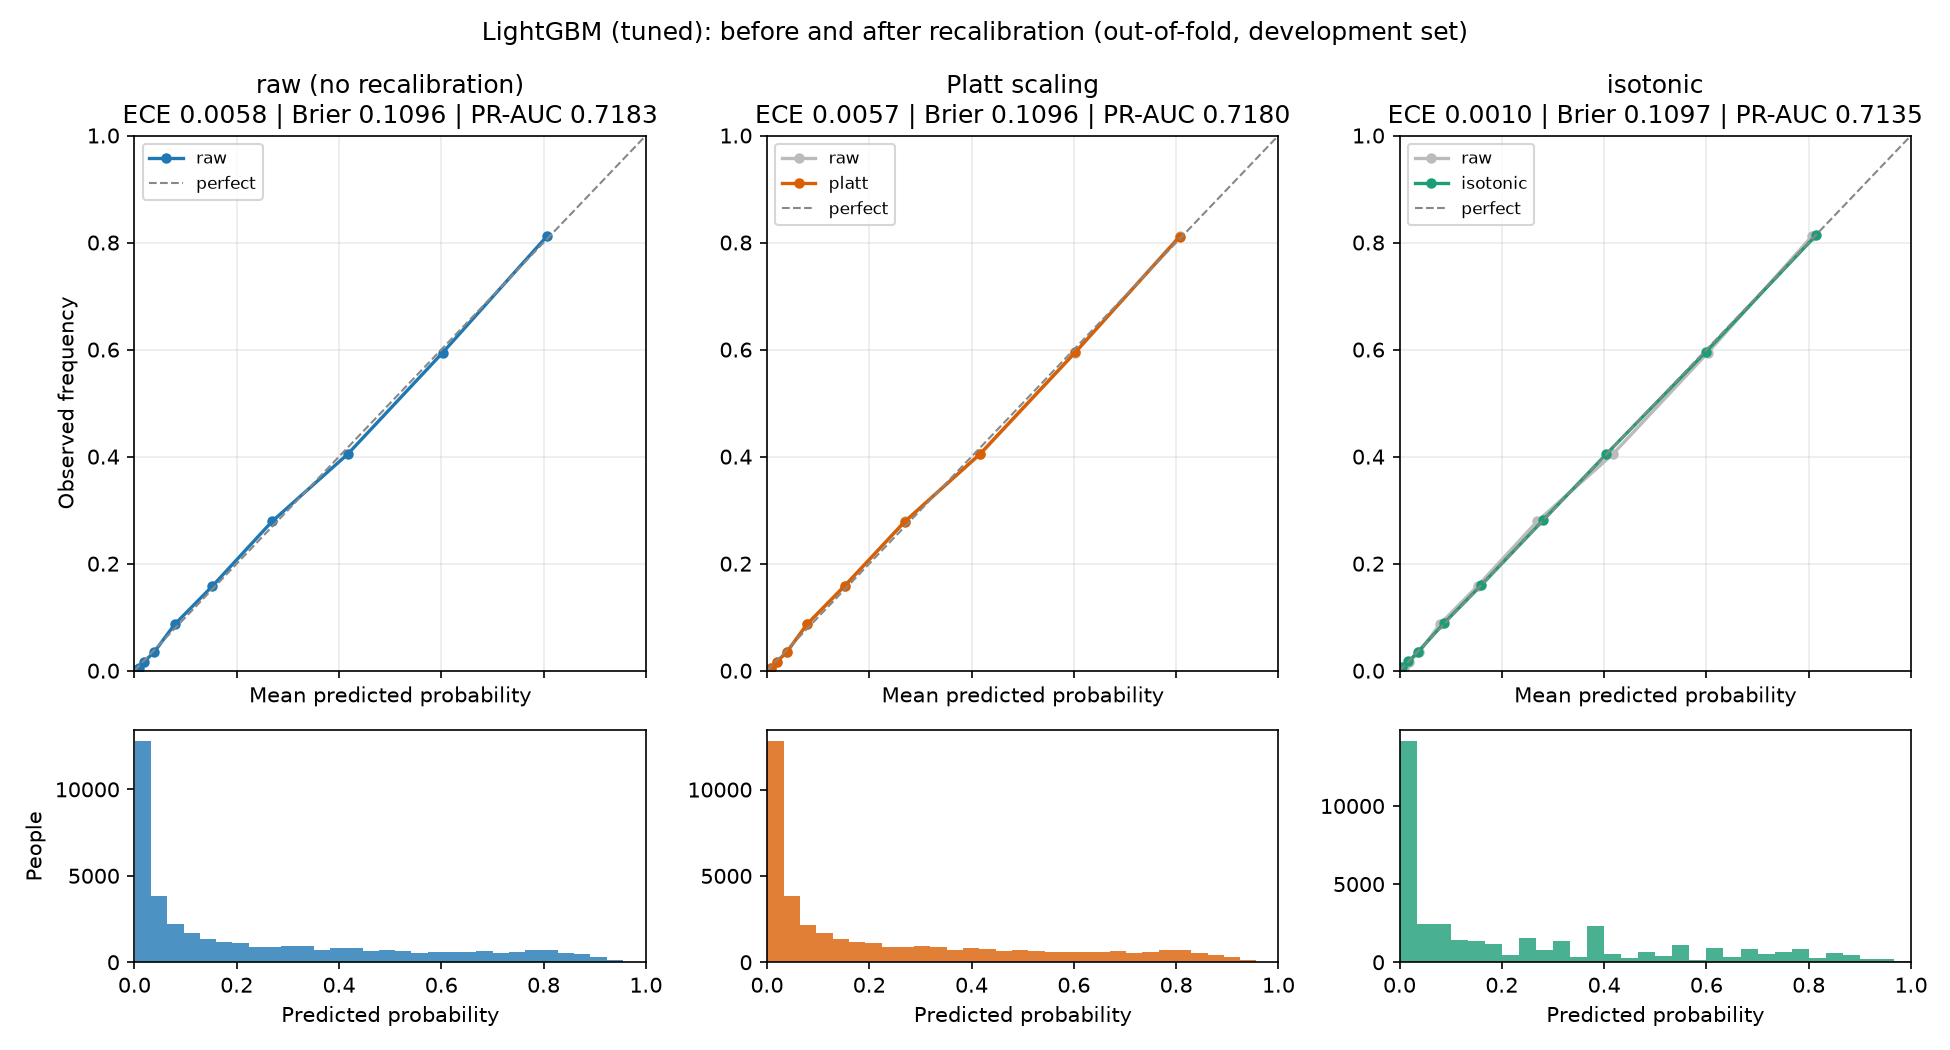

In [3]:
display(Image(str(REPORTS / "calibration_lightgbm_comparison.png")))

### Reading

(v1 numbers: findings F22-F24 in `docs/findings_log.md`, same script on the v1
parameters.)

- **LightGBM v2 is already calibrated, before any recalibration.** Raw ECE
  0.0058 (v1: 0.030), the level of the logistic regression (0.0059); Brier
  0.1096, the lowest of the three models. The reliability curve sits on the
  diagonal. In the top 10%, the model predicts 0.807 and 0.812 are high
  earners (v1: 0.835 vs 0.813, over-confident).
- **Why:** v1 used `scale_pos_weight` 1.32, which counts every high earner
  1.32 times in the loss and so pushes every probability up. v2 fixes it at 1
  (notebook 04, section 3), so LightGBM minimises the plain log-loss, whose
  minimum is reached by true probabilities (S7). The random forest tells the
  same story: removing its class weights took its ECE from 0.132 (v1) to
  0.011 (v2).
- **Platt scaling now does nothing:** ECE 0.0057, Brier 0.1096, PR-AUC 0.7183
  → 0.7180. There is nothing left to correct.
- **Isotonic gives the lowest ECE (0.0010) but costs ranking** (PR-AUC 0.7183 →
  0.7135): its step function gives the same probability to many people (ties).
  The figure shows it: the raw and Platt histograms are smooth and almost
  identical, the isotonic one is spiky, while the three reliability curves lie
  on top of each other. Not worth it when the raw model is already calibrated.
- **By sex, the raw probabilities mean the same for women and men on
  average:** women predicted 0.112 vs observed 0.109, men 0.302 vs 0.304 (v1:
  0.132 vs 0.109 and 0.337 vs 0.304, over-predicted for both and more for
  women in relative terms). ECE 0.010 for both groups. The Brier score is lower
  for women (0.061 vs 0.134) only because their base rate is lower, not
  because their probabilities are better.
- **Note on PR-AUC:** 0.7183 here vs 0.7189 in notebook 04. Here the PR-AUC is
  computed once on all pooled out-of-fold predictions; in notebook 04 it is the
  mean of the 5 per-fold values. Both are correct; they measure slightly
  different things.
- **Caveat:** the parameters were tuned on these same folds, so these numbers
  are slightly optimistic (S5). The calibration is checked once more on the
  test set (section 3).

**Decision:** LightGBM v2 does **not need recalibration**; its raw
probabilities are used as they are. `src/fairness.py` still applies Platt to
LightGBM: with v2 this is harmless (same probabilities), to keep or remove as a
team decision. Details: finding F41 in `docs/findings_log.md`.

## 2. Explainability (SHAP) — to do

Which inputs drive the predictions of LightGBM v2, overall and for women vs
men? (S8; hypothesis of the project: marital status, occupation and hours act
as proxies for sex, F30-F31.)

## 3. Test set, once — to do

Final metrics of LightGBM v2 (and the logistic regression benchmark) on the
locked 20% test set: PR-AUC, ROC-AUC, Brier, ECE, overall and by sex; fairness
before / after mitigation; model card.